In [ ]:
import pandas as pd

# Load the analysis-ready dataset
flights = pd.read_csv("data/cleaned/analysis_ready_flights.csv")

# Check the dataset dimensions
print("Dataset shape:", flights.shape)

# Check the column names
print(flights.columns.tolist())

Dataset shape: (327346, 34)
['year', 'month', 'day', 'dep_time', 'sched_dep_time', 'dep_delay', 'arr_time', 'sched_arr_time', 'arr_delay', 'carrier', 'flight', 'tailnum', 'origin', 'dest', 'air_time', 'distance', 'hour', 'minute', 'time_hour', 'season', 'scheduled_hour', 'year_weather', 'month_weather', 'day_weather', 'hour_weather', 'temp', 'dewp', 'humid', 'wind_dir', 'wind_speed', 'wind_gust', 'precip', 'pressure', 'visib']


In [ ]:
# Check missing values in the Model 1 variables
model1_variables = [
    "arr_delay",
    "season",
    "carrier",
    "scheduled_hour",
    "distance",
    "origin"
]

print(flights[model1_variables].isna().sum())

# Check the categories in each categorical variable
print("\nSeason categories:")
print(flights["season"].value_counts())

print("\nAirlines:")
print(flights["carrier"].nunique())
print(flights["carrier"].value_counts())

print("\nOrigin airports:")
print(flights["origin"].value_counts())

arr_delay         0
season            0
carrier           0
scheduled_hour    0
distance          0
origin            0
dtype: int64

Season categories:
season
Summer    84124
Spring    83594
Fall      82599
Winter    77029
Name: count, dtype: int64

Airlines:
16
carrier
UA    57782
B6    54049
EV    51108
DL    47658
AA    31947
MQ    25037
US    19831
9E    17294
WN    12044
VX     5116
FL     3175
AS      709
F9      681
YV      544
HA      342
OO       29
Name: count, dtype: int64

Origin airports:
origin
EWR    117127
JFK    109079
LGA    101140
Name: count, dtype: int64


In [ ]:
# Create a separate dataset for Model 1
model1_data = flights[
    ["arr_delay", "season", "carrier", "scheduled_hour", "distance", "origin"]
].copy()

# Set the reference categories
model1_data["season"] = pd.Categorical(
    model1_data["season"],
    categories=["Winter", "Spring", "Summer", "Fall"]
)

model1_data["carrier"] = pd.Categorical(
    model1_data["carrier"],
    categories=["AA", "AS", "B6", "DL", "EV", "F9", "FL", "HA",
                "MQ", "OO", "UA", "US", "VX", "WN", "YV", "9E"]
)

model1_data["origin"] = pd.Categorical(
    model1_data["origin"],
    categories=["JFK", "LGA", "EWR"]
)

# Convert categorical variables into dummy variables
model1_data = pd.get_dummies(
    model1_data,
    columns=["season", "carrier", "origin"],
    drop_first=True,
    dtype=int
)

# Check the prepared dataset
print("Model 1 dataset shape:", model1_data.shape)
print(model1_data.head())
print("\nData types:")
print(model1_data.dtypes)

Model 1 dataset shape: (327346, 23)
   arr_delay  scheduled_hour  distance  season_Spring  season_Summer  \
0       11.0               5      1400              0              0   
1       20.0               5      1416              0              0   
2       33.0               5      1089              0              0   
3      -18.0               5      1576              0              0   
4      -25.0               6       762              0              0   

   season_Fall  carrier_AS  carrier_B6  carrier_DL  carrier_EV  ...  \
0            0           0           0           0           0  ...   
1            0           0           0           0           0  ...   
2            0           0           0           0           0  ...   
3            0           0           1           0           0  ...   
4            0           0           0           1           0  ...   

   carrier_MQ  carrier_OO  carrier_UA  carrier_US  carrier_VX  carrier_WN  \
0           0           0  

In [ ]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 2.8 MB/s  0:00:046m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 30.3 MB/s  0:00:016m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [statsmodels] [statsmodels]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import statsmodels.api as sm

y = model1_data["arr_delay"]
X = model1_data.drop(columns=["arr_delay"])
X = sm.add_constant(X)

model1 = sm.OLS(y, X).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:              arr_delay   R-squared:                       0.058
Model:                            OLS   Adj. R-squared:                  0.058
Method:                 Least Squares   F-statistic:                     918.8
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:13:19   Log-Likelihood:            -1.6981e+06
No. Observations:              327346   AIC:                         3.396e+06
Df Residuals:                  327323   BIC:                         3.396e+06
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            -17.4022      0.427    -40.

The model includes 327,346 flights and examines how season, airline, scheduled departure hour, flight distance, and origin airport relate to arrival delays. The model explains 5.8% of the variation in arrival delays. The results show some differences across seasons, airlines, and airports. Further diagnostics are needed to check the model's reliability.

In [ ]:
The following diagnostics evaluate potential multicollinearity among predictors 
and assess the assumptions of the regression model.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()

vif_data["Variable"] = X.columns
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data.sort_values("VIF", ascending=False))

          Variable       VIF
9       carrier_EV  2.953432
15      carrier_UA  2.894629
22      origin_EWR  2.625609
7       carrier_B6  2.478384
8       carrier_DL  2.135957
21      origin_LGA  1.940076
13      carrier_MQ  1.773154
2         distance  1.700524
20      carrier_9E  1.671396
16      carrier_US  1.633225
4    season_Summer  1.555593
3    season_Spring  1.553203
5      season_Fall  1.551934
18      carrier_WN  1.397410
17      carrier_VX  1.210033
11      carrier_FL  1.113943
12      carrier_HA  1.050099
6       carrier_AS  1.042473
10      carrier_F9  1.025024
19      carrier_YV  1.022200
1   scheduled_hour  1.017129
14      carrier_OO  1.001282
0            const  1.000000


The VIF results were all below 5, which means the variables in the model are not too closely related to each other. Based on these results, we kept all the variables in Model 1.

In [ ]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 19.0 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 23.9 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 22.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 25.8 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


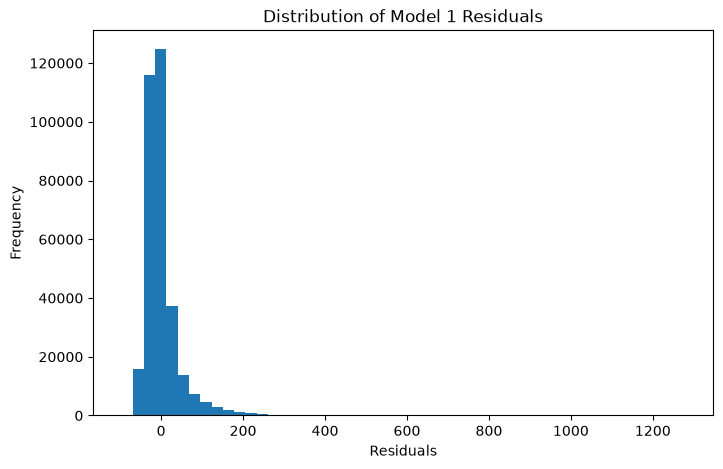

In [ ]:
import matplotlib.pyplot as plt

residuals = model1.resid

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=50)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Model 1 Residuals")
plt.show()

Most of the residuals are close to zero, but there is a long tail on the right side. This means the model has some much larger prediction errors, especially for flights with longer delays.

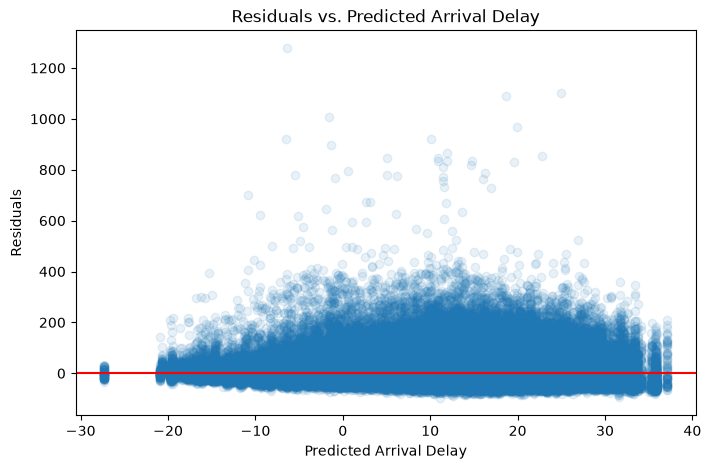

In [ ]:
fitted_values = model1.fittedvalues

plt.figure(figsize=(8, 5))
plt.scatter(fitted_values, residuals, alpha=0.1)
plt.axhline(y=0, color="red")
plt.xlabel("Predicted Arrival Delay")
plt.ylabel("Residuals")
plt.title("Residuals vs. Predicted Arrival Delay")
plt.show()

The residuals have different levels of spread across the predicted values, with some very large errors. This suggests that the model's errors are not consistent across all flights.

In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(model1.resid, model1.model.exog)

print("LM Statistic:", bp_test[0])
print("P-value:", bp_test[1])

LM Statistic: 2475.9229457598576
P-value: 0.0


The model's errors don't have a consistent spread (p < 0.001). This means the model predicts some flights more accurately than others, with larger errors for certain flights.

In [ ]:
model1_robust = model1.get_robustcov_results(cov_type="HC3")

print(model1_robust.summary())

                            OLS Regression Results                            
Dep. Variable:              arr_delay   R-squared:                       0.058
Model:                            OLS   Adj. R-squared:                  0.058
Method:                 Least Squares   F-statistic:                     879.6
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:22:03   Log-Likelihood:            -1.6981e+06
No. Observations:              327346   AIC:                         3.396e+06
Df Residuals:                  327323   BIC:                         3.396e+06
Df Model:                          22                                         
Covariance Type:                  HC3                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            -17.4022      0.402    -43.

We also ran the regression using robust standard errors to account for the differences in prediction errors. The main results stayed the same, with only small changes in standard errors and p-values. The model still explains 5.8% of the variation in arrival delays.

In [ ]:
from statsmodels.stats.outliers_influence import OLSInfluence

influence = OLSInfluence(model1)

cooks_distance = influence.cooks_distance[0]

print("Highest Cook's Distance:", cooks_distance.max())
print("Flights with Cook's Distance above 4/n:",
      (cooks_distance > 4 / len(model1_data)).sum())

Highest Cook's Distance: 0.11174929799751122
Flights with Cook's Distance above 4/n: 12321


The Cook's Distance test identified 12,321 flights above the 4/n reference threshold. These flights may have some influence on the regression results, so they should be considered when evaluating the model. However, they were not removed from the dataset.

In [ ]:
top_influence = pd.DataFrame({
    "Cook's Distance": cooks_distance,
    "Flight Index": model1_data.index
})

top_influence = top_influence.sort_values(
    "Cook's Distance", ascending=False
).head(10)

print(top_influence)

        Cook's Distance  Flight Index
7008           0.111749          7008
116533         0.023135        116533
236112         0.015536        236112
297644         0.011498        297644
25109          0.008361         25109
46476          0.006251         46476
138797         0.005041        138797
240784         0.003970        240784
208827         0.003616        208827
208988         0.002561        208988


In [ ]:
top_flights = flights.loc[top_influence["Flight Index"], [
    "month", "day", "carrier", "flight",
    "origin", "dest", "arr_delay", "dep_delay", "distance"
]]

print(top_flights)

        month  day carrier  flight origin dest  arr_delay  dep_delay  distance
7008        1    9      HA      51    JFK  HNL     1272.0     1301.0      4983
116533      2   10      F9     835    LGA  DEN      834.0      853.0      1620
236112      6   22      OO    4528    EWR  DTW      157.0      131.0       488
297644      8   28      OO    5568    LGA  CLE      140.0      154.0       419
25109       1   30      OO    8500    LGA  ORD      107.0       67.0       733
46476      10   22      YV    2693    LGA  CLT      381.0      387.0       544
138797      3    8      F9     797    LGA  DEN      410.0      430.0      1620
240784      6   27      YV    2751    LGA  CLT      328.0      340.0       544
208827      5   23      F9     507    LGA  DEN      345.0      272.0      1620
208988      5   23      F9     837    LGA  DEN      300.0      308.0      1620


In [ ]:
weather_columns = [
    col for col in flights.columns
    if any(word in col.lower() for word in [
        "temp", "humid", "wind", "precip", "pressure",
        "visibility", "weather", "rain", "snow", "cloud"
    ])
]

print(weather_columns)

['year_weather', 'month_weather', 'day_weather', 'hour_weather', 'temp', 'humid', 'wind_dir', 'wind_speed', 'wind_gust', 'precip', 'pressure']


In [ ]:
weather_cols = [
    "temp", "humid", "wind_dir", "wind_speed",
    "wind_gust", "precip", "pressure"
]

missing_weather = pd.DataFrame({
    "Missing Values": flights[weather_cols].isna().sum(),
    "Missing %": (flights[weather_cols].isna().mean() * 100).round(2)
})

print(missing_weather)

            Missing Values  Missing %
temp                  1544       0.47
humid                 1544       0.47
wind_dir              9574       2.92
wind_speed            1605       0.49
wind_gust           249912      76.34
precip                1527       0.47
pressure             36142      11.04


In [ ]:
weather_without_gust = [
    "temp", "humid", "wind_dir",
    "wind_speed", "precip", "pressure"
]

weather_with_gust = weather_without_gust + ["wind_gust"]

print("Flights with all weather data (excluding gust):",
      flights[weather_without_gust].dropna().shape[0])

print("Flights with all weather data (including gust):",
      flights[weather_with_gust].dropna().shape[0])

print("Total flights:", len(flights))

Flights with all weather data (excluding gust): 284550
Flights with all weather data (including gust): 72734
Total flights: 327346


In [ ]:
model2_cols = [
    "arr_delay", "season", "carrier", "scheduled_hour",
    "distance", "origin", "temp", "humid",
    "wind_dir", "wind_speed", "precip", "pressure"
]

model2_sample = flights[model2_cols].dropna()

print("Model 2 complete-case sample:", len(model2_sample))
print("Flights excluded:", len(flights) - len(model2_sample))

Model 2 complete-case sample: 284550
Flights excluded: 42796


We ran Model 1 again using only the 284,550 flights that have complete weather data. This way, both Model 1 and Model 2 can use the same flights, making it easier to compare their results. The R-squared went down slightly from 0.058 to 0.054 after using the smaller dataset.

We also ran the model with robust standard errors to account for the differences in prediction errors. The R-squared and regression results stayed the same, but some standard errors and p-values changed slightly. This gives us more reliable results when looking at the model's statistical significance.

In [ ]:
model1_comparison_data = model2_sample[
    ["arr_delay", "season", "carrier", "scheduled_hour",
     "distance", "origin"]
].copy()

model1_comparison_data["season"] = pd.Categorical(
    model1_comparison_data["season"],
    categories=["Winter", "Spring", "Summer", "Fall"]
)

model1_comparison_data["carrier"] = pd.Categorical(
    model1_comparison_data["carrier"],
    categories=["AA", "AS", "B6", "DL", "EV", "F9", "FL", "HA",
                "MQ", "OO", "UA", "US", "VX", "WN", "YV", "9E"]
)

model1_comparison_data["origin"] = pd.Categorical(
    model1_comparison_data["origin"],
    categories=["JFK", "LGA", "EWR"]
)

model1_comparison_data = pd.get_dummies(
    model1_comparison_data,
    columns=["season", "carrier", "origin"],
    drop_first=True,
    dtype=int
)

y_comparison = model1_comparison_data["arr_delay"]
X_comparison = model1_comparison_data.drop(columns=["arr_delay"])
X_comparison = sm.add_constant(X_comparison)

model1_comparison = sm.OLS(y_comparison, X_comparison).fit()

model1_comparison_robust = model1_comparison.get_robustcov_results(
    cov_type="HC3"
)

print(model1_comparison_robust.summary())



                            OLS Regression Results                            
Dep. Variable:              arr_delay   R-squared:                       0.054
Model:                            OLS   Adj. R-squared:                  0.053
Method:                 Least Squares   F-statistic:                     687.3
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:29:42   Log-Likelihood:            -1.4594e+06
No. Observations:              284550   AIC:                         2.919e+06
Df Residuals:                  284527   BIC:                         2.919e+06
Df Model:                          22                                         
Covariance Type:                  HC3                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            -17.2633      0.406    -42.

We ran Model 1 again using the 284,550 flights that also have complete weather data. This allows us to compare both models using the same flights. We kept the same variables and reference categories as the original Model 1 and also used robust standard errors.

Regression notebook summary: 

We first ran the regression using 327,346 flights. The model explained 5.8% of the differences in arrival delays.

We checked how well the model worked and found that some flights had much larger prediction errors than others. We also found that the errors were not consistent across all flights.

We kept all flights in the dataset, including those with unusually long delays.

We then ran Model 1 again using 284,550 flights that had complete weather data. This way, we can compare Model 1 and Model 2 using the same flights. With this smaller dataset, the model explained 5.4% of the differences in arrival delays.